# Ensemble

**Idea:** train several networks and average their predictions. The group is often better than any single member.

In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

#fixed seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [2]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [3]:
# A simple neural network: 784 pixels -> 256 -> 128 -> 10 classes
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

In [4]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Step 1: Train 3 networks with different random seeds

In [5]:
models = []
rows = []
total_time = 0
for seed in [11, 22, 33]:
    print("--- seed", seed)
    torch.manual_seed(seed)   # different seed = different starting weights
    model = MLP()
    hist, secs = train(model, train_loader)
    total_time += secs
    models.append(model)
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"model": f"mlp_seed_{seed}", "test_accuracy": test_acc, "test_loss": test_loss})

--- seed 11
epoch 1/3  train_loss=0.6473  val_loss=0.4717  val_acc=0.8290
epoch 2/3  train_loss=0.4300  val_loss=0.4406  val_acc=0.8423
epoch 3/3  train_loss=0.3794  val_loss=0.4189  val_acc=0.8520
--- seed 22
epoch 1/3  train_loss=0.6572  val_loss=0.4746  val_acc=0.8393
epoch 2/3  train_loss=0.4448  val_loss=0.4389  val_acc=0.8337
epoch 3/3  train_loss=0.3828  val_loss=0.3924  val_acc=0.8610
--- seed 33
epoch 1/3  train_loss=0.6528  val_loss=0.4995  val_acc=0.8190
epoch 2/3  train_loss=0.4382  val_loss=0.4302  val_acc=0.8473
epoch 3/3  train_loss=0.3827  val_loss=0.4475  val_acc=0.8393


## Step 2: Average their predicted probabilities

In [6]:
def get_probs(model, loader):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(torch.softmax(model(x), dim=1))
            labels.append(y)
    return torch.cat(probs), torch.cat(labels)

all_probs = []
for m in models:
    p, labels = get_probs(m, test_loader)
    all_probs.append(p)

ensemble_probs = torch.stack(all_probs).mean(dim=0)   # average over the 3 models
ensemble_acc = (ensemble_probs.argmax(1) == labels).float().mean().item()
ensemble_loss = nn.functional.nll_loss(torch.log(ensemble_probs), labels).item()

rows.append({"model": "ensemble", "test_accuracy": ensemble_acc, "test_loss": ensemble_loss})
results = pd.DataFrame(rows)
results.to_csv("outputs/ensemble_results.csv", index=False)
print(results)
print("Total training time for all 3 models: %.1f s" % total_time)

         model  test_accuracy  test_loss
0  mlp_seed_11         0.8280   0.465000
1  mlp_seed_22         0.8430   0.431854
2  mlp_seed_33         0.8305   0.478040
3     ensemble         0.8562   0.407862
Total training time for all 3 models: 24.8 s


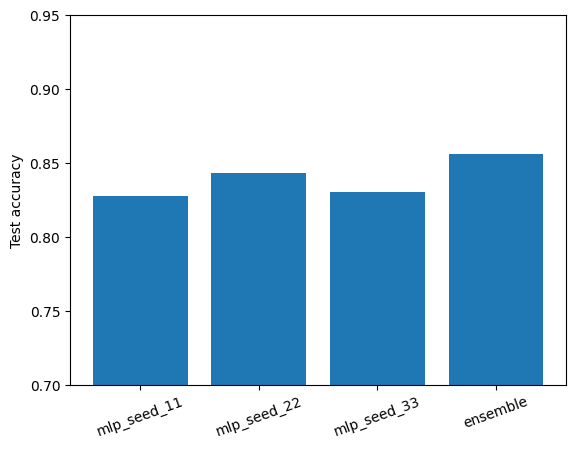

In [7]:
plt.bar(results["model"], results["test_accuracy"])
plt.ylabel("Test accuracy")
plt.ylim(0.7, 0.95)
plt.xticks(rotation=20)
plt.savefig("outputs/test_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()